# Notebook Preprocesamiento y Pruebas de Modelos
Este notebook contiene el preprocesamiento propuesto para los datos a partir del EDA realizado. Este consta de: reordenar los scans para reconstruir correctamente la columna cervical en cada estudio, convertit cada píxel a HU, aplica ventana ósea y retorna un formato ultraligero (uint8) para evitar sobrecargar el cpu y la memoria disponible en el work, homogeneiza el volumen y entrenar la segméntación a partir de los 87 estudios que cuentan con esta información. Posterior a ello se segmentan los 2019 estudios disponibles para poder entrenar al modelo que detecta fracturas en cada una de las vertebras.

En estos modelos se pretende maximizar el Recall debido a la necesidad de reducir los falsos negativos que podría resultar más peligroso para el paciente. Es importante tomar en cuenta que es necesario ejecutar este notebook desde el editor de kaggle y que toma aproximadamente 3-4 horas en generar el mejor modelo. Sin embargo, a partir de la crua de aprendizaje es posible determinar que el modelo sufre de sobreajuste por lo que no resulta del todo útil para la clasificación de fracturas. 

## 0. Configuración

### A. Librerías

In [ ]:
!pip install -q "monai[all]"

In [14]:
!pip install -q pylibjpeg pylibjpeg-libjpeg pylibjpeg-openjpeg

In [15]:
!pip install -q python-gdcm pylibjpeg pylibjpeg-libjpeg

In [4]:
#!pip uninstall -y nvimgcodec pynvimgcodec

In [16]:
import monai
print(monai.__version__)

1.6.1


In [17]:
import os
import glob
import gc
import pandas as pd
import torch
import scipy.ndimage
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pydicom
from monai.networks.nets import UNet
from monai.losses import DiceLoss
from monai.metrics import DiceMetric
from monai.data import CacheDataset, DataLoader, decollate_batch
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Orientationd,
    Spacingd,
    Resized,
    ScaleIntensityRangePercentilesd,
    AsDiscrete
)
from tqdm import tqdm

### B. Parámetros 

In [6]:
# Configuración visual
sns.set_theme(style="whitegrid")

# Rutas
base_dir = "/kaggle/input/competitions/rsna-2022-cervical-spine-fracture-detection"
path_train = os.path.join(base_dir, "train.csv")
image_dir = os.path.join(base_dir, "train_images")
seg_dir = os.path.join(base_dir, "segmentations")
output_dir = "/kaggle/working/processed_volumes_unet"

### C. Funciones

#### Preprocesamiento

**Reordenar los cortes:** Esta función busca reordenar los cortes para que representen correctamente la columna cervical. 

In [7]:
# ==========================================
# PASO 1: EXTRACCIÓN Y ORDENAMIENTO ESPACIAL
# ==========================================
def obtener_rutas_y_espaciado(study_uid, image_dir):
    """
    Ordena los cortes por la coordenada Z anatómica y calcula el espaciado físico original.
    """
    study_path = os.path.join(image_dir, study_uid)
    archivos_dcm = [f for f in os.listdir(study_path) if f.endswith('.dcm')]
    
    cortes = []
    pixel_spacing = None
    
    for archivo in archivos_dcm:
        ruta_completa = os.path.join(study_path, archivo)
        dcm = pydicom.dcmread(ruta_completa, stop_before_pixels=True)
        z_pos = float(dcm.ImagePositionPatient[2])
        
        if pixel_spacing is None and hasattr(dcm, 'PixelSpacing'):
            pixel_spacing = [float(dcm.PixelSpacing[0]), float(dcm.PixelSpacing[1])]
            
        cortes.append((z_pos, ruta_completa))
    
    # Ordenamiento estricto por coordenada Z
    cortes.sort(key=lambda x: x[0])
    rutas_ordenadas = [corte[1] for corte in cortes]
    
    # Calcular el espaciado Z real
    z_posiciones = [corte[0] for corte in cortes]
    if len(z_posiciones) > 1:
        z_spacing = np.median(np.abs(np.diff(z_posiciones)))
    else:
        z_spacing = 1.0 
        
    espaciado_original = np.array([z_spacing, pixel_spacing[0], pixel_spacing[1]])
    
    return rutas_ordenadas, espaciado_original

Reordenar las vertebras y "normalizar" para reducir el efecto de la distribución binormal de slice thickness y los outliers de "pixel_spacing". Luego la función preprocesar_datase_completo aplica estos cambios a todo el dataset. 

In [8]:
# ==========================================
# PASO 2: ACONDICIONAMIENTO DE LA SEÑAL (HU)
# ==========================================
def procesar_corte_dicom_optimizado(ruta_dicom, window_center=400, window_width=1800):
    """
    Convierte el píxel a HU, aplica ventana ósea y retorna un formato ultraligero (uint8).
    """
    dcm = pydicom.dcmread(ruta_dicom)
    # Temporalmente en float32 para las operaciones matemáticas
    image = dcm.pixel_array.astype(np.float32)
    
    intercept = getattr(dcm, 'RescaleIntercept', 0)
    slope = getattr(dcm, 'RescaleSlope', 1)
    
    hu_image = image * slope + intercept
    
    img_min = window_center - (window_width / 2) # -500
    img_max = window_center + (window_width / 2) # 1300
    
    windowed_image = np.clip(hu_image, img_min, img_max)
    
    # Normalización (0 a 1)
    img_normalized = (windowed_image - img_min) / (img_max - img_min)
    
    # Conversión vital a uint8 (0 a 255) para reducir el tamaño al 25%
    return (img_normalized * 255).astype(np.uint8)

Homogeneizar el volumne para evitar acabarse la memoria del work.

In [9]:
# ==========================================
# PASO 3: REMUESTREO VOLUMÉTRICO (ISOTRÓPICO)
# ==========================================
def remuestrear_volumen_optimizado(volumen_3d, espaciado_original, espaciado_objetivo=np.array([1.0, 1.0, 1.0])):
    """
    Homogeneiza el volumen y asegura que la salida no infle la memoria RAM.
    """
    factor_redimension = espaciado_original / espaciado_objetivo
    
    volumen_remuestreado = scipy.ndimage.zoom(
        volumen_3d, 
        factor_redimension, 
        order=1, 
        mode='nearest'
    )
    
    # Forzar nuevamente a uint8 tras la interpolación de scipy
    return volumen_remuestreado.astype(np.uint8)

Orquestador para aplicar el preprocesamiento al dataset segmentado (87 estudios).

In [10]:
def generar_dataset_unet(path_train, image_dir, seg_dir, output_dir):
    """
    Procesa exclusivamente los 87 estudios que cuentan con segmentación y gestiona la RAM.
    """
    os.makedirs(output_dir, exist_ok=True)
    df_train = pd.read_csv(path_train)
    
    # 1. IDENTIFICAR LOS 87 ESTUDIOS (Filtro salvavidas para Kaggle)
    archivos_seg = glob.glob(os.path.join(seg_dir, "*.nii"))
    uids_segmentados = [os.path.basename(f).replace(".nii", "") for f in archivos_seg]
    
    # Cruzar con train.csv por seguridad
    uids_a_procesar = df_train[df_train['StudyInstanceUID'].isin(uids_segmentados)]['StudyInstanceUID'].unique()
    
    print(f"Iniciando procesamiento de {len(uids_a_procesar)} estudios con máscara...")
    
    for uid in tqdm(uids_a_procesar, desc="Preprocesando"):
        rutas_ordenadas, espaciado_original = obtener_rutas_y_espaciado(uid, image_dir)
        
        volumen_procesado = []
        for ruta in rutas_ordenadas:
            img = procesar_corte_dicom_optimizado(ruta)
            volumen_procesado.append(img)
            
        volumen_3d = np.stack(volumen_procesado)
        
        # 2. HOMOGENEIZACIÓN FÍSICA
        volumen_isotropico = remuestrear_volumen_optimizado(volumen_3d, espaciado_original)
        
        # 3. GUARDADO COMPRIMIDO
        output_path = os.path.join(output_dir, f"{uid}.npz")
        np.savez_compressed(output_path, vol=volumen_isotropico)
        
        # 4. LIMPIEZA EXTREMA DE RAM (Evita el congelamiento)
        del volumen_procesado
        del volumen_3d
        del volumen_isotropico
        gc.collect() # Invoca al recolector de basura de Python   

## 1. Preprocesamiento

In [11]:
generar_dataset_unet(path_train, image_dir, seg_dir, output_dir)

Iniciando procesamiento de 87 estudios con máscara...


Preprocesando: 100%|██████████| 87/87 [12:26<00:00,  8.58s/it]


## 2. Entrenamiento Modelos

### Clasificador Multiclase de Fractura

**Fase 1**

Generar el modelo que mejor segmenta entre vertebras de una columna cervical eliminando ruido de fondo, i.e, piel y otros tejidos que no sean hueso.

In [13]:
import os
import glob
import pandas as pd
import torch
import gc
from monai.networks.nets import UNet
from monai.losses import DiceLoss
from monai.metrics import DiceMetric
from monai.data import CacheDataset, DataLoader, decollate_batch
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Orientationd,
    Resized, ScaleIntensityRangePercentilesd, AsDiscrete
)

# 1. Configuración de Rutas
base_dir = "/kaggle/input/competitions/rsna-2022-cervical-spine-fracture-detection"
seg_dir = os.path.join(base_dir, "segmentations")
unet_data_dir = "/kaggle/working/processed_volumes_unet"

# 2. Separación estricta de conjuntos
df_bbox = pd.read_csv(os.path.join(base_dir, "train_bounding_boxes.csv"))
uids_con_caja = set(df_bbox['StudyInstanceUID'].unique())
archivos_seg = glob.glob(os.path.join(seg_dir, "*.nii"))
uids_seg = [os.path.basename(f).replace(".nii", "") for f in archivos_seg]

train_files, val_files = [], []
for uid in uids_seg:
    img_path = os.path.join(unet_data_dir, f"{uid}.npz")
    seg_path = os.path.join(seg_dir, f"{uid}.nii")
    
    if not os.path.exists(img_path): continue
        
    item = {"image": img_path, "label": seg_path}
    if uid in uids_con_caja:
        val_files.append(item)
    else:
        train_files.append(item)

print(f"Estudios U-Net -> Entrenamiento: {len(train_files)} | Validación: {len(val_files)}")

from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Orientationd,
    Resized, ScaleIntensityRangePercentilesd, AsDiscrete,
    Lambdad # <-- Nueva importación
)

# 3. Transformaciones actualizadas
unet_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys=["image", "label"]),
    Orientationd(keys=["image", "label"], axcodes="RAS"),
    
    # NUEVO: Convertir vértebras torácicas (8-19) en fondo (0) 
    # para que las etiquetas encajen en los 8 canales de salida
    Lambdad(
        keys="label", 
        func=lambda x: torch.where(x > 7, torch.zeros_like(x), x)
    ),
    
    Resized(keys=["image", "label"], spatial_size=(128, 128, 128), mode=("trilinear", "nearest")),
    ScaleIntensityRangePercentilesd(keys="image", lower=1, upper=99, b_min=0.0, b_max=1.0, clip=True)
])

train_loader = DataLoader(CacheDataset(train_files, transform=unet_transforms), batch_size=2, shuffle=True)
val_loader = DataLoader(CacheDataset(val_files, transform=unet_transforms), batch_size=2, shuffle=False)

# 4. Arquitectura y Optimizadores
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_unet = UNet(
    spatial_dims=3, in_channels=1, out_channels=8, 
    channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2), num_res_units=2
).to(device)

loss_function = DiceLoss(to_onehot_y=True, softmax=True)
optimizer = torch.optim.Adam(model_unet.parameters(), 1e-4)
dice_metric = DiceMetric(include_background=False, reduction="mean")

# 5. Bucle de Entrenamiento
best_metric = -1
max_epochs = 30

for epoch in range(max_epochs):
    model_unet.train()
    for batch_data in train_loader:
        inputs, labels = batch_data["image"].to(device), batch_data["label"].to(device)
        optimizer.zero_grad()
        loss = loss_function(model_unet(inputs), labels)
        loss.backward()
        optimizer.step()
    
    model_unet.eval()
    with torch.no_grad():
        for val_data in val_loader:
            val_inputs, val_labels = val_data["image"].to(device), val_data["label"].to(device)
            val_outputs = [AsDiscrete(argmax=True, to_onehot=8)(i) for i in decollate_batch(model_unet(val_inputs))]
            val_labels = [AsDiscrete(to_onehot=8)(i) for i in decollate_batch(val_labels)]
            dice_metric(y_pred=val_outputs, y=val_labels)
        
        metric = dice_metric.aggregate().item()
        dice_metric.reset()
        if metric > best_metric:
            best_metric = metric
            torch.save(model_unet.state_dict(), "/kaggle/working/best_unet3d.pth")
            print(f"Epoch {epoch+1:02d} | Nuevo mejor Dice: {best_metric:.4f} (Guardado)")

# Liberar memoria tras entrenar
del model_unet, train_loader, val_loader
gc.collect()
torch.cuda.empty_cache()

monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.


Estudios U-Net -> Entrenamiento: 47 | Validación: 40


Loading dataset: 100%|██████████| 40/40 [02:10<00:00,  3.26s/it]


Epoch 01 | Nuevo mejor Dice: 0.0054 (Guardado)
Epoch 02 | Nuevo mejor Dice: 0.0056 (Guardado)
Epoch 03 | Nuevo mejor Dice: 0.0068 (Guardado)
Epoch 04 | Nuevo mejor Dice: 0.0102 (Guardado)
Epoch 05 | Nuevo mejor Dice: 0.0185 (Guardado)
Epoch 06 | Nuevo mejor Dice: 0.0343 (Guardado)
Epoch 07 | Nuevo mejor Dice: 0.0511 (Guardado)
Epoch 08 | Nuevo mejor Dice: 0.0532 (Guardado)
Epoch 09 | Nuevo mejor Dice: 0.0622 (Guardado)
Epoch 10 | Nuevo mejor Dice: 0.0722 (Guardado)
Epoch 11 | Nuevo mejor Dice: 0.0762 (Guardado)
Epoch 12 | Nuevo mejor Dice: 0.0980 (Guardado)
Epoch 13 | Nuevo mejor Dice: 0.1030 (Guardado)
Epoch 14 | Nuevo mejor Dice: 0.1165 (Guardado)
Epoch 18 | Nuevo mejor Dice: 0.1497 (Guardado)
Epoch 19 | Nuevo mejor Dice: 0.1584 (Guardado)
Epoch 20 | Nuevo mejor Dice: 0.1800 (Guardado)
Epoch 21 | Nuevo mejor Dice: 0.1860 (Guardado)
Epoch 22 | Nuevo mejor Dice: 0.1988 (Guardado)
Epoch 24 | Nuevo mejor Dice: 0.2050 (Guardado)
Epoch 25 | Nuevo mejor Dice: 0.2213 (Guardado)
Epoch 29 | Nu

La segmentación no resulta óptima ya que en general se obtiene un dice menor a 0.25 ya que no se están segmentando objetos microscópicos.

**Fase 2**

En esta fase se pretende aplicar la segmentación a los 2019 estudios con el mejor modelo generado en la fase anterior.

In [19]:
import os
import gc
import torch
import numpy as np
import pandas as pd
import torch.nn.functional as F
from tqdm import tqdm
from monai.networks.nets import UNet

# 1. Configuración
base_dir = "/kaggle/input/competitions/rsna-2022-cervical-spine-fracture-detection"
image_dir = os.path.join(base_dir, "train_images")
cropped_dir = "/kaggle/working/cropped_volumes"
os.makedirs(cropped_dir, exist_ok=True)

df_train = pd.read_csv(os.path.join(base_dir, "train.csv"))
todos_uids = df_train['StudyInstanceUID'].unique()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_unet = UNet(spatial_dims=3, in_channels=1, out_channels=8, channels=(16, 32, 64, 128, 256), strides=(2, 2, 2, 2), num_res_units=2).to(device)
model_unet.load_state_dict(torch.load("/kaggle/input/datasets/rodrigoaroche/bestunet/best_unet3d.pth"))
model_unet.eval()

with torch.no_grad():
    for uid in tqdm(todos_uids, desc="Localizando y Recortando (Acelerado por GPU)"):
        output_path = os.path.join(cropped_dir, f"{uid}.npz")
        if os.path.exists(output_path): continue 
            
        try:
            # A. Leer y apilar directamente el volumen original (sin scipy)
            rutas, espaciado = obtener_rutas_y_espaciado(uid, image_dir)
            vol_raw = np.stack([procesar_corte_dicom_optimizado(r) for r in rutas]) # (Z, 512, 512) en uint8
            
            # B. Enviar a GPU y submuestrear a 128³ a velocidad luz con PyTorch
            tensor_raw = torch.tensor(vol_raw, dtype=torch.float32, device=device).unsqueeze(0).unsqueeze(0) / 255.0
            tensor_128 = F.interpolate(tensor_raw, size=(128, 128, 128), mode='trilinear', align_corners=False)
            
            # C. Inferencia
            pred_mask = torch.argmax(model_unet(tensor_128), dim=1).squeeze().cpu().numpy()
            nonzero_indices = np.argwhere(pred_mask > 0)
            
            if len(nonzero_indices) == 0:
                continue 
                
            # D. Mapear coordenadas de 128³ de vuelta a la forma ORIGINAL (Z, 512, 512)
            z_min, y_min, x_min = nonzero_indices.min(axis=0)
            z_max, y_max, x_max = nonzero_indices.max(axis=0)
            
            scale_z, scale_y, scale_x = vol_raw.shape[0]/128.0, vol_raw.shape[1]/128.0, vol_raw.shape[2]/128.0
            
            z0, z1 = max(0, int(z_min * scale_z)), min(vol_raw.shape[0], int(z_max * scale_z))
            y0, y1 = max(0, int(y_min * scale_y)), min(vol_raw.shape[1], int(y_max * scale_y))
            x0, x1 = max(0, int(x_min * scale_x)), min(vol_raw.shape[2], int(x_max * scale_x))
            
            # E. Recortar primero, hacer isotrópico después
            tensor_recortado = tensor_raw[:, :, z0:z1, y0:y1, x0:x1]
            
            # F. Calcular dimensiones isotrópicas basadas en el espaciado físico
            target_z = int(tensor_recortado.shape[2] * espaciado[0])
            target_y = int(tensor_recortado.shape[3] * espaciado[1])
            target_x = int(tensor_recortado.shape[4] * espaciado[2])
            
            # Interpolación GPU sobre un volumen diminuto
            tensor_iso = F.interpolate(tensor_recortado, size=(target_z, target_y, target_x), mode='trilinear', align_corners=False)
            
            # G. Devolver a CPU, formato uint8 y guardar
            vol_final = (tensor_iso.squeeze().cpu().numpy() * 255).astype(np.uint8)
            np.savez_compressed(output_path, vol=vol_final)
            
        except Exception as e:
            print(f"\nError en UID {uid}: {e}")
            
        # Limpieza estricta
        for var in ['vol_raw', 'tensor_raw', 'tensor_128', 'tensor_recortado', 'tensor_iso', 'vol_final']:
            if var in locals(): del locals()[var]
        gc.collect()
        torch.cuda.empty_cache()

Localizando y Recortando (Acelerado por GPU):  71%|███████   | 1433/2019 [3:43:52<1:25:33,  8.76s/it]


Error en UID 1.2.826.0.1.3680043.20756: Input and output sizes should be greater than 0, but got input (D: 490, H: 256, W: 328) output (D: 0, H: 91, W: 117)


Localizando y Recortando (Acelerado por GPU): 100%|██████████| 2019/2019 [5:02:44<00:00,  9.00s/it]  


**Fase 3**

En esta fase se pretende probar el entrenamiento de varios modelos intentando maximizar el recall y generando una curva de aprendizaje para determinar si el modelo sufre de sobreajuste.

Estudios disponibles para clasificación: 2018 de 2019
Cargando datos en memoria caché...


Loading dataset: 100%|██████████| 404/404 [01:05<00:00,  6.16it/s]



Iniciando entrenamiento del Clasificador Final...
Epoch 01 | Train Loss: 1.8784 | Val Loss: 1.9895 | Recall: 0.9914 -> (Nuevo Mejor Guardado)
Epoch 02 | Train Loss: 1.8073 | Val Loss: 1.8853 | Recall: 1.0000 -> (Nuevo Mejor Guardado)
Epoch 03 | Train Loss: 1.8047 | Val Loss: 2.0614 | Recall: 0.9895
Epoch 04 | Train Loss: 1.7962 | Val Loss: 1.9240 | Recall: 0.9922
Epoch 05 | Train Loss: 1.7919 | Val Loss: 1.8599 | Recall: 1.0000
Epoch 06 | Train Loss: 1.7765 | Val Loss: 1.9028 | Recall: 0.9920
Epoch 07 | Train Loss: 1.7742 | Val Loss: 1.9328 | Recall: 0.9957
Epoch 08 | Train Loss: 1.7689 | Val Loss: 1.8906 | Recall: 0.9957
Epoch 09 | Train Loss: 1.7649 | Val Loss: 1.8697 | Recall: 0.9957
Epoch 10 | Train Loss: 1.7448 | Val Loss: 1.8812 | Recall: 1.0000
Epoch 11 | Train Loss: 1.7367 | Val Loss: 1.8957 | Recall: 0.9922
Epoch 12 | Train Loss: 1.7273 | Val Loss: 1.8883 | Recall: 0.9980
Epoch 13 | Train Loss: 1.7135 | Val Loss: 1.9229 | Recall: 0.9980
Epoch 14 | Train Loss: 1.6909 | Val Los

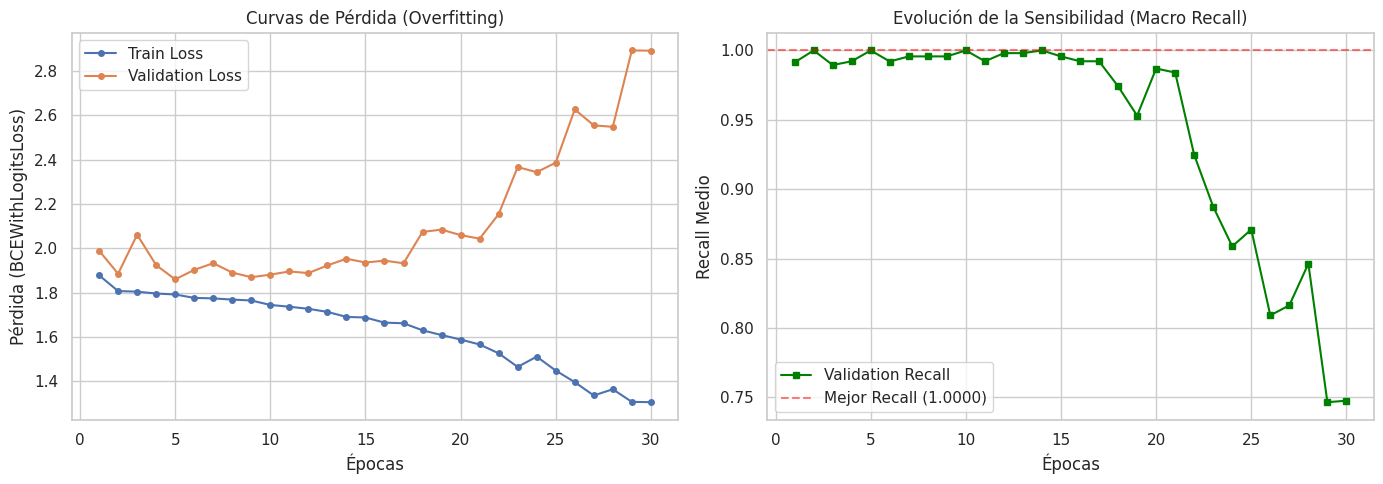

In [20]:
import os
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import recall_score
from monai.networks.nets import DenseNet121
from monai.data import CacheDataset, DataLoader
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Resized,
    ScaleIntensityRangePercentilesd, RandAffined, RandGaussianNoised
)

# 1. Configuración y Filtrado Dinámico de Datos
base_dir = "/kaggle/input/competitions/rsna-2022-cervical-spine-fracture-detection"
cropped_dir = "/kaggle/working/cropped_volumes"

df_train = pd.read_csv(os.path.join(base_dir, "train.csv"))

# Filtrar estrictamente solo los pacientes que fueron recortados con éxito en la Fase 2
uids_disponibles = [f.replace(".npz", "") for f in os.listdir(cropped_dir) if f.endswith(".npz")]
df_filtered = df_train[df_train['StudyInstanceUID'].isin(uids_disponibles)].reset_index(drop=True)

print(f"Estudios disponibles para clasificación: {len(df_filtered)} de {len(df_train)}")

# 2. Estratificación
# Usamos StratifiedKFold (cada fila es un paciente único)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_idx, val_idx) in enumerate(skf.split(df_filtered, df_filtered['patient_overall'])):
    df_filtered.loc[val_idx, 'fold'] = fold

# Separar Train y Validation (Fold 0 para validar)
train_df = df_filtered[df_filtered['fold'] != 0].reset_index(drop=True)
val_df = df_filtered[df_filtered['fold'] == 0].reset_index(drop=True)

# 3. Preparación de DataLoaders (MONAI)
def prep_dicts(df):
    return [{"image": os.path.join(cropped_dir, f"{r.StudyInstanceUID}.npz"), 
             "label": np.array([r.patient_overall, r.C1, r.C2, r.C3, r.C4, r.C5, r.C6, r.C7], dtype=np.float32)} 
            for _, r in df.iterrows()]

train_transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Resized(keys=["image"], spatial_size=(96, 96, 96)), # Resolución óptima para DenseNet en Kaggle
    ScaleIntensityRangePercentilesd(keys="image", lower=1, upper=99, b_min=0.0, b_max=1.0, clip=True),
    RandAffined(keys=["image"], prob=0.5, rotate_range=(0.2, 0.2, 0.2)),
    RandGaussianNoised(keys=["image"], prob=0.1)
])

val_transforms = Compose([
    LoadImaged(keys=["image"]),
    EnsureChannelFirstd(keys=["image"]),
    Resized(keys=["image"], spatial_size=(96, 96, 96)),
    ScaleIntensityRangePercentilesd(keys="image", lower=1, upper=99, b_min=0.0, b_max=1.0, clip=True)
])

# CacheDataset acelera las épocas guardando los volúmenes en RAM tras la primera lectura
print("Cargando datos en memoria caché...")
train_loader = DataLoader(CacheDataset(prep_dicts(train_df), transform=train_transforms), batch_size=4, shuffle=True)
val_loader = DataLoader(CacheDataset(prep_dicts(val_df), transform=val_transforms), batch_size=4, shuffle=False)

# 4. Arquitectura y Ponderación para Alta Sensibilidad (Minimizar Falsos Negativos)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
classifier = DenseNet121(spatial_dims=3, in_channels=1, out_channels=8).to(device)

# Cálculo matemático de pesos por clase
pos_counts = train_df[['patient_overall', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7']].values.sum(axis=0)
neg_counts = len(train_df) - pos_counts
penalty_factor = 2.5 # Castiga fuertemente las fracturas que el modelo ignore
pos_weights = torch.tensor((neg_counts / pos_counts) * penalty_factor, dtype=torch.float32).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weights)
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-4, weight_decay=1e-5)

# 5. Bucle de Entrenamiento y Monitoreo
DECISION_THRESHOLD = 0.3 # Umbral más permisivo
max_epochs = 30
best_val_recall = 0.0

hist_train_loss, hist_val_loss, hist_val_recall = [], [], []

print("\nIniciando entrenamiento del Clasificador Final...")
for epoch in range(max_epochs):
    classifier.train()
    train_loss = 0.0
    
    for batch in train_loader:
        optimizer.zero_grad()
        loss = criterion(classifier(batch["image"].to(device)), batch["label"].to(device))
        loss.backward()
        optimizer.step()
        train_loss += loss.item()
        
    avg_train_loss = train_loss / len(train_loader)
    hist_train_loss.append(avg_train_loss)
        
    # Validación
    classifier.eval()
    val_loss = 0.0
    val_preds_probs, val_trues = [], []
    
    with torch.no_grad():
        for batch in val_loader:
            inputs, labels = batch["image"].to(device), batch["label"].to(device)
            outputs = classifier(inputs)
            val_loss += criterion(outputs, labels).item()
            
            val_preds_probs.append(torch.sigmoid(outputs).cpu().numpy())
            val_trues.append(labels.cpu().numpy())
            
    avg_val_loss = val_loss / len(val_loader)
    hist_val_loss.append(avg_val_loss)
            
    val_preds_probs = np.vstack(val_preds_probs)
    val_trues = np.vstack(val_trues)
    
    # Calcular Recall general
    val_preds_binary = (val_preds_probs > DECISION_THRESHOLD).astype(int)
    recalls = [recall_score(val_trues[:, i], val_preds_binary[:, i], zero_division=0) for i in range(8)]
    mean_recall = np.mean(recalls)
    hist_val_recall.append(mean_recall)
    
    status = ""
    if mean_recall > best_val_recall:
        best_val_recall = mean_recall
        torch.save(classifier.state_dict(), "/kaggle/working/best_recall_classifier.pth")
        status = " -> (Nuevo Mejor Guardado)"
        
    print(f"Epoch {epoch+1:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Recall: {mean_recall:.4f}{status}")

# 6. Dibujo de las Curvas de Aprendizaje
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 5))

# Gráfico 1: Evaluar Sobreajuste (Overfitting)
plt.subplot(1, 2, 1)
plt.plot(range(1, max_epochs + 1), hist_train_loss, label='Train Loss', marker='o', markersize=4)
plt.plot(range(1, max_epochs + 1), hist_val_loss, label='Validation Loss', marker='o', markersize=4)
plt.title('Curvas de Pérdida (Overfitting)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (BCEWithLogitsLoss)')
plt.legend()

# Gráfico 2: Evolución de la Sensibilidad
plt.subplot(1, 2, 2)
plt.plot(range(1, max_epochs + 1), hist_val_recall, label='Validation Recall', color='green', marker='s', markersize=4)
plt.axhline(y=best_val_recall, color='red', linestyle='--', alpha=0.5, label=f'Mejor Recall ({best_val_recall:.4f})')
plt.title('Evolución de la Sensibilidad (Macro Recall)')
plt.xlabel('Épocas')
plt.ylabel('Recall Medio')
plt.legend()

plt.tight_layout()
plt.show()

En general el modelo obtiene muy buen recall sin embargo este va decayendo con el paso de épocas, lo mismo sucede con la curva de aprendizaje hay una clara diferencia entre el conjunto de validación y de entrenamiento. La curva del conjunto de entrenamiento es decreciente mientras que la del conjunto de validación sigue una tendencia creciente "rebotando" hacia arribam por lo que es posible concluir que el modelo se memoriza los datos de entrenamiento y por eso su curva decrece, por lo que no es capaz de generalizar por lo que la curva del conjunto de validación es creciente y tiene una mayor péridida, esto quiere decir que el modelo está sobreajustado. 